#**GHI CHÚ:**
 + Các mục lớn 1,2,3... là các mục lớn, bên trong nó sẽ còn có chi nhỏ (người được phụ trách tự chia), ví dụ 4.1, 4.2, ... sau đó là các cell code.
 + Sau khi train phải lưu:
    - Accuracy
    - Precision
    - Recall
    - F1-score
    - Confusion Matrix
    - Classification Report

Đặc biệt ưu tiên Macro F1 đối với dataset mất cân bằng.

In [1]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Tạo và cấu hình thư mục làm việc Project1 trên Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Project1"
os.makedirs(PROJECT_DIR, exist_ok=True)
print(f"Thư mục làm việc trên Google Drive: {PROJECT_DIR}")


Mounted at /content/drive
Thư mục làm việc trên Google Drive: /content/drive/MyDrive/Project1


#1. Cài đặt các thư viện cần thiết

In [2]:
!pip install -q transformers datasets accelerate sentencepiece
!pip install -q scikit-learn pandas numpy matplotlib seaborn
!pip install -q emoji

#2. Kiểm tra thư viện

In [3]:
import transformers
import datasets
import sklearn
import pandas
import numpy

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)

Transformers: 5.22.1
Datasets: 4.8.5
Scikit-learn: 1.6.1
Pandas: 2.2.3
NumPy: 2.4.6


#3. Kiểm tra PhoBERT

In [4]:
from transformers import AutoTokenizer, AutoModel

model_name = "vinai/phobert-base-v2"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

print("PhoBERT loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


PhoBERT loaded successfully!


#4. Tiền xủ lý dữ liệu (tiền xử lý, tokenizer, chuyển nhãn) - Hưng, Hoàng Minh, Minh Tú


# 4.1 Làm sạch Text

In [5]:
import os
import re
import pandas as pd
import emoji

from datasets import load_dataset, concatenate_datasets
from huggingface_hub import login

# ============================================================
# 0. ĐĂNG NHẬP HUGGING FACE
# ============================================================

hf_token = None

# Ưu tiên lấy Token từ Google Colab Secrets
try:
    from google.colab import userdata
    hf_token = userdata.get('HF_TOKEN')
except Exception:
    pass

# Nếu không có trong Colab Secrets, lấy từ biến môi trường
if not hf_token:
    hf_token = os.environ.get("HF_TOKEN")

# Nếu vẫn chưa có Token, yêu cầu nhập trực tiếp
if not hf_token:
    from getpass import getpass
    hf_token = getpass("Nhập Hugging Face Access Token: ")

# Đăng nhập Hugging Face
login(token=hf_token)

print("Đăng nhập Hugging Face thành công!")

# ============================================================
# 1. TẢI DATASET TOXICITY: tarudesu/ViCTSD
# ============================================================

print("Đang tải các dataset trực tiếp từ Hugging Face...")

print("- [1/3] Đang tải dataset Toxicity (tarudesu/ViCTSD)...")

ds_toxic = load_dataset(
    "tarudesu/ViCTSD",
    token=hf_token
)

df_toxic = concatenate_datasets([
    ds_toxic['train'],
    ds_toxic['test'],
    ds_toxic['validation']
]).to_pandas()

df_toxic = df_toxic[['Comment', 'Toxicity']].rename(
    columns={
        'Comment': 'text',
        'Toxicity': 'label_raw'
    }
)

df_toxic['task'] = 'toxicity'

# ============================================================
# 2. TẢI DATASET HATE SPEECH: uitnlp/vihsd
# ============================================================

print("- [2/3] Đang tải dataset Hate Speech (uitnlp/vihsd)...")

ds_hate = load_dataset(
    "uitnlp/vihsd",
    token=hf_token
)

print("  -> Tải thành công dataset uitnlp/vihsd!")

df_hate = concatenate_datasets([
    ds_hate['train'],
    ds_hate['test'],
    ds_hate['validation']
]).to_pandas()

text_col_hate = 'free_text' if 'free_text' in df_hate.columns else 'text'
label_col_hate = 'label_id' if 'label_id' in df_hate.columns else 'label'

df_hate = df_hate[[text_col_hate, label_col_hate]].rename(
    columns={
        text_col_hate: 'text',
        label_col_hate: 'label_raw'
    }
)

df_hate['task'] = 'hate_speech'

# ============================================================
# 3. TẢI DATASET SENTIMENT: ura-hcmut/UIT-VSFC
# ============================================================

print("- [3/3] Đang tải dataset Sentiment (ura-hcmut/UIT-VSFC)...")

ds_sentiment = load_dataset(
    "ura-hcmut/UIT-VSFC",
    token=hf_token
)

df_sent = concatenate_datasets([
    ds_sentiment['train'],
    ds_sentiment['test'],
    ds_sentiment['validation']
]).to_pandas()

# Tự động xác định cột văn bản
text_col = [
    col for col in ['sentence', 'Sentence', 'text', 'Comment']
    if col in df_sent.columns
][0]

label_col = 'sentiment' if 'sentiment' in df_sent.columns else 'label'

df_sent = df_sent[[text_col, label_col]].rename(
    columns={
        text_col: 'text',
        label_col: 'label_raw'
    }
)

df_sent['task'] = 'sentiment'

# ============================================================
# 4. GỘP VÀ LÀM SẠCH DỮ LIỆU
# ============================================================

df = pd.concat(
    [df_toxic, df_hate, df_sent],
    ignore_index=True
)

print(f"\nTổng số dòng văn bản thu thập từ 3 dataset: {len(df)}")

# Lọc bỏ giá trị rỗng
df = df.dropna(subset=['text', 'label_raw'])

# Loại bỏ dữ liệu trùng lặp
df = df.drop_duplicates(
    subset=['task', 'text', 'label_raw']
).reset_index(drop=True)

print(f"Số dòng sau khi lọc rỗng và trùng lặp: {len(df)}")

Đăng nhập Hugging Face thành công!
Đang tải các dataset trực tiếp từ Hugging Face...
- [1/3] Đang tải dataset Toxicity (tarudesu/ViCTSD)...


README.md:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

ViCTSD_train.csv:   0%|          | 0.00/1.69M [00:00<?, ?B/s]

ViCTSD_valid.csv:   0%|          | 0.00/496k [00:00<?, ?B/s]

ViCTSD_test.csv:   0%|          | 0.00/239k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7000 [00:00<?, ? examples/s]

... (15 outputs left out)

Generating train split:   0%|          | 0/11426 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1584 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3166 [00:00<?, ? examples/s]


Tổng số dòng văn bản thu thập từ 3 dataset: 59576
Số dòng sau khi lọc rỗng và trùng lặp: 56958


In [6]:
# Cài đặt thư viện tách từ và đọc file excel nếu chưa có:
!pip install -q pyvi openpyxl

import os
import re
import pandas as pd
from pyvi import ViTokenizer

# 1. Từ điển chuẩn hóa teencode tiếng Việt thông dụng
# Khởi tạo từ điển mặc định bổ trợ
teencode_dict = {
    "ko": "không", "k": "không", "kh": "không", "hok": "không", "hong": "không",
    "dc": "được", "dk": "được", "đc": "được",
    "vs": "với", "j": "gì", "r": "rồi", "cx": "cũng",
    "thik": "thích", "thjx": "thích", "mik": "mình",
    "t": "tao", "m": "mày", "ae": "anh em",
    "ng": "người", "ntn": "như thế nào", "sao": "sao",
    "đt": "điện thoại", "fb": "facebook", "ib": "nhắn tin",
    "bt": "bình thường"
}

# Áp dụng file Project1/teencode.xlsx trên Google Drive vào từ điển
teencode_excel_path = "/content/drive/MyDrive/Project1/teencode.xlsx"
search_paths = [teencode_excel_path, "teencode.xlsx", "Project1/teencode.xlsx"]
excel_found = None
for p in search_paths:
    if os.path.exists(p):
        excel_found = p
        break

if excel_found:
    try:
        df_teencode = pd.read_excel(excel_found)
        # Chuẩn hóa tên các cột (xóa khoảng trắng thừa)
        df_teencode.columns = [str(col).strip() for col in df_teencode.columns]

        # Nhận diện cột theo cấu trúc file: STT | Teencode | Nghĩa | Dạng chuẩn hóa | Loại teencode
        tc_col = next((c for c in df_teencode.columns if 'teencode' in c.lower()), df_teencode.columns[1])
        norm_col = next((c for c in df_teencode.columns if 'chuẩn hóa' in c.lower() or 'chuan hoa' in c.lower()), None)
        meaning_col = next((c for c in df_teencode.columns if 'nghĩa' in c.lower() or 'nghia' in c.lower()), None)

        loaded_count = 0
        for _, row in df_teencode.iterrows():
            if pd.isna(row[tc_col]):
                continue
            k = str(row[tc_col]).strip().lower()
            if not k or k == "nan":
                continue

            # Ưu tiên lấy từ cột "Dạng chuẩn hóa", nếu trống thì lấy cột "Nghĩa"
            val = None
            if norm_col and pd.notna(row[norm_col]):
                val = str(row[norm_col]).strip()
            elif meaning_col and pd.notna(row[meaning_col]):
                val = str(row[meaning_col]).strip()

            if val and val != "nan":
                # Làm sạch chú thích ngữ cảnh trong ngoặc đơn nếu có (vd: "với ơi (nhấn)" -> "với ơi", "nhiều (nhấn)" -> "nhiều")
                val_clean = re.sub(r'\(.*?\)', '', val).strip()
                # Nếu có nhiều nghĩa ngăn cách bằng dấu '/' (vd: "xin chào / cười" -> lấy nghĩa chính đầu tiên "xin chào")
                if '/' in val_clean:
                    val_clean = val_clean.split('/')[0].strip()
                teencode_dict[k] = val_clean.lower() if val_clean else val.strip().lower()
                loaded_count += 1

        print(f"✅ Đã nạp thành công {loaded_count} từ teencode từ file: {excel_found}")
        print(f"Tổng số từ trong từ điển teencode_dict: {len(teencode_dict)}")
    except Exception as e:
        print(f"⚠️ Lỗi khi đọc file {excel_found}: {e}. Sử dụng từ điển teencode mặc định.")
else:
    print(f"⚠️ Không tìm thấy file {teencode_excel_path}. Sử dụng từ điển teencode mặc định.")

def replace_teencode(text):
    words = text.split()
    return " ".join([teencode_dict.get(w, w) for w in words])

def process_emoji(text):
    # Nếu muốn dịch emoji sang text tiếng Anh, có thể dùng demojize:
    # return emoji.demojize(text, delimiters=(" ", " "))
    # Hoặc để nguyên emoji/chuẩn hóa tùy bài toán. Tạm thời giữ hàm nếu bạn cần:
    return emoji.demojize(text, delimiters=(" ", " "))

def clean_text(text):
    if not isinstance(text, str):
        return ""

    # 1. Chuyển chữ thường
    text = text.lower()

    # 2. Xóa URL (sửa regex chuẩn để không khớp nhầm từ)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 3. Xóa mention (@username) và hashtag (#tag)
    text = re.sub(r'[@#]\w+', '', text)

    # 4. Rút gọn ký tự lặp quá 2 lần (vd: "ngonnnn" -> "ngon")
    text = re.sub(r'([a-zà-ỹ])\1{2,}', r'\1', text)

    # 5. Rút gọn dấu câu bị spam lặp lại (vd: "???" -> "?", "!!!!" -> "!")
    text = re.sub(r'([.?!])\1+', r'\1', text)

    # 6. Chuẩn hóa teencode
    text = replace_teencode(text)

    # 7. Xóa ký tự lạ/rác, NHƯNG GIỮ LẠI: chữ, số, tiếng Việt và các dấu . , ? !
    text = re.sub(r'[^0-9a-zà-ỹ\s.,?!]', ' ', text)

    # 8. Tách khoảng trắng quanh dấu câu để tránh dính liền từ
    text = re.sub(r'\s*([.,?!])\s*', r' \1 ', text)

    # 9. Chuẩn hóa khoảng trắng thừa
    text = re.sub(r'\s+', ' ', text).strip()

    # 10. TÁCH TỪ TIẾNG VIỆT (Bắt buộc chuẩn theo PhoBERT)
    # Ví dụ: "rất tuyệt vời !" -> "rất tuyệt_vời !"
    text = ViTokenizer.tokenize(text)

    return text


✅ Đã nạp thành công 777 từ teencode từ file: /content/drive/MyDrive/Project1/teencode.xlsx
Tổng số từ trong từ điển teencode_dict: 784


In [7]:
print("Đang tiến hành làm sạch văn bản...")
df['text_cleaned'] = df['text'].apply(clean_text)

# Lọc bỏ các dòng bị rỗng sau khi làm sạch
df = df[df['text_cleaned'].str.strip() != ""].reset_index(drop=True)

# Hiển thị đối chiếu 5 dòng đầu
print("\n--- ĐỐI CHIẾU TRƯỚC VÀ SAU LÀM SẠCH ---")
for i in range(min(5, len(df))):
    print(f"Gốc : {df.loc[i, 'text']}")
    print(f"Sạch: {df.loc[i, 'text_cleaned']}")
    print("-" * 50)

# Lưu checkpoint ra Google Drive vào thư mục Project1 để Người 2 phụ trách mục 4.2 dùng tiếp
output_dir = "/content/drive/MyDrive/Project1"
os.makedirs(output_dir, exist_ok=True)
output_path = f"{output_dir}/df_cleaned.csv"
df.to_csv(output_path, index=False)
print(f"\n[Hoàn thành 4.1] Đã lưu dữ liệu tại: {output_path}")


Đang tiến hành làm sạch văn bản...

--- ĐỐI CHIẾU TRƯỚC VÀ SAU LÀM SẠCH ---
Gốc : Thật tuyệt vời...!!!
Sạch: thật tuyệt_vời . !
--------------------------------------------------
Gốc : mỹ đã tuột dốc quá nhiều rồi, giờ muốn vực dậy cũng rất khó
Sạch: mỹ đã tuột_dốc quá nhiều rồi , giờ muốn vực dậy cũng rất khó
--------------------------------------------------
Gốc : tôi thấy người lái xe hơi bấm còi mới là người "rất" lịch sự "quá" văn minh.đường xá là của chung,người cùng sử dụng kiên nhẫn cùng nhau dùng. bấm còi nháy đèn đòi ưu tiên tôi phải được đi trước. thật quá là anh đại mà.
Sạch: tôi thấy người lái xe_hơi bấm còi mới là người rất lịch_sự quá văn_minh . đường_xá là của chung , người cùng sử_dụng kiên_nhẫn cùng nhau dùng . bấm còi nháy đèn đòi ưu_tiên tôi phải được đi trước . thật quá là anh đại mà .
--------------------------------------------------
Gốc : Coi dịch là giặc. Đã mang tên đó mà xâm nhập VN thì phải đầu hàng hoặc cút xéo. VN luôn tự hào!
Sạch: coi dịch là giặc . đã 

# 4.2 Tách từ và tokenize

In [8]:
# Cài đặt thư viện cần thiết
!pip install pyvi transformers matplotlib seaborn pandas -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyvi import ViTokenizer
from transformers import AutoTokenizer

In [9]:
# Đọc file dữ liệu đã làm sạch từ Mục 4.1 trong folder Project1
input_path = "/content/drive/MyDrive/Project1/df_cleaned.csv"
try:
    df = pd.read_csv(input_path)
    print(f"Đã tải dữ liệu từ Google Drive: {input_path}")
except Exception as e:
    print(f"Không tìm thấy file trên Drive ({input_path}), thử đọc file local 'df_cleaned.csv'...")
    df = pd.read_csv("df_cleaned.csv")

# Đảm bảo các dòng rỗng (NaN) ở cột text_cleaned được xử lý
df['text_cleaned'] = df['text_cleaned'].fillna('')

# Tiến hành tách từ ghép tiếng Việt bằng pyvi
print("Đang tiến hành tách từ ghép tiếng Việt (ViTokenizer)...")
df['text_segmented'] = df['text_cleaned'].apply(lambda x: ViTokenizer.tokenize(str(x)))

# Lưu kết quả ra file df_segmented.csv trong folder Project1 trên Google Drive
output_dir = "/content/drive/MyDrive/Project1"
os.makedirs(output_dir, exist_ok=True)
output_path = f"{output_dir}/df_segmented.csv"
df.to_csv(output_path, index=False)
df.to_csv("df_segmented.csv", index=False) # Bản sao local
print(f"Đã lưu file kết quả tại: {output_path}")

# Kiểm tra thử 3 dòng đầu
df[['task', 'text_cleaned', 'text_segmented']].head(3)


Đã tải dữ liệu từ Google Drive: /content/drive/MyDrive/Project1/df_cleaned.csv
Đang tiến hành tách từ ghép tiếng Việt (ViTokenizer)...
Đã lưu file kết quả tại: /content/drive/MyDrive/Project1/df_segmented.csv


,task,text_cleaned,text_segmented
0,toxicity,thật tuyệt_vời . !,thật tuyệt_vời . !
1,toxicity,"mỹ đã tuột_dốc quá nhiều rồi , giờ muốn vực dậ...","mỹ đã tuột_dốc quá nhiều rồi , giờ muốn vực dậ..."
2,toxicity,tôi thấy người lái xe_hơi bấm còi mới là người...,tôi thấy người lái xe_hơi bấm còi mới là người...


Đang tải tokenizer của PhoBERT (vinai/phobert-base-v2)...
Đang tính toán độ dài token của toàn bộ tập dữ liệu...


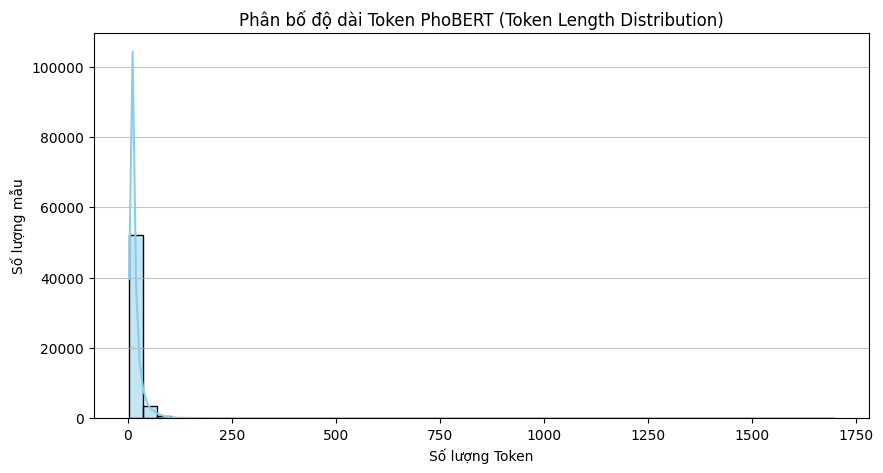

--- THỐNG KÊ ĐỘ DÀI TOKEN ---
- Tổng số mẫu: 56757
- Độ dài lớn nhất: 1697 tokens
- 95% câu có độ dài <= 46 tokens
- 99% câu có độ dài <= 85 tokens


In [10]:
# Khởi tạo PhoBERT Tokenizer (sử dụng model_name đã khai báo ở Mục 3)
print(f"Đang tải tokenizer của PhoBERT ({model_name})...")
# Không cần dùng token=True vì đây là mô hình public
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Tính độ dài token của từng câu trong cột text_segmented
print("Đang tính toán độ dài token của toàn bộ tập dữ liệu...")
token_lengths = [len(tokenizer.encode(text, truncation=False)) for text in df['text_segmented']]

# Vẽ biểu đồ phân bố độ dài token
plt.figure(figsize=(10, 5))
sns.histplot(token_lengths, bins=50, kde=True, color='skyblue')
plt.title('Phân bố độ dài Token PhoBERT (Token Length Distribution)')
plt.xlabel('Số lượng Token')
plt.ylabel('Số lượng mẫu')
plt.grid(axis='y', alpha=0.75)
plt.show()

# Thống kê các mốc quan trọng
max_len_found = max(token_lengths)
p95 = int(np.percentile(token_lengths, 95))
p99 = int(np.percentile(token_lengths, 99))

print(f"--- THỐNG KÊ ĐỘ DÀI TOKEN ---")
print(f"- Tổng số mẫu: {len(token_lengths)}")
print(f"- Độ dài lớn nhất: {max_len_found} tokens")
print(f"- 95% câu có độ dài <= {p95} tokens")
print(f"- 99% câu có độ dài <= {p99} tokens")

In [11]:
# Chốt tham số MAX_LEN (Bao phủ ~95-99% dữ liệu, không vượt quá 256 để tránh tràn RAM/GPU)
MAX_LEN = min(256, max(p95, 64))
print(f"CHỐT THAM SỐ MAX_LEN = {MAX_LEN}")

# Hàm tokenize chuẩn cho PhoBERT
def tokenize_func(texts, max_length=MAX_LEN):
    """
    Hàm tokenize nhận vào danh sách/Series văn bản đã tách từ (text_segmented)
    và trả về Dictionary chứa input_ids và attention_mask dạng PyTorch Tensor.
    """
    return tokenizer(
        list(texts),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

# Test thử hàm tokenize_func trên 2 mẫu đầu tiên
sample_tokens = tokenize_func(df['text_segmented'].head(2))
print("\n[Kiểm tra chạy thử tokenize_func]:")
print("- Shape input_ids:", sample_tokens['input_ids'].shape)
print("- Shape attention_mask:", sample_tokens['attention_mask'].shape)
print("\nHOÀN THÀNH MỤC 4.2!")

CHỐT THAM SỐ MAX_LEN = 64

[Kiểm tra chạy thử tokenize_func]:
- Shape input_ids: torch.Size([2, 64])
- Shape attention_mask: torch.Size([2, 64])

HOÀN THÀNH MỤC 4.2!


# 4.3 Nhãn và đóng gói

In [12]:

# =====================================
# 4.3 - BƯỚC 1: KIỂM TRA NHÃN
# =====================================

print("1. SỐ LƯỢNG DỮ LIỆU MỖI BÀI TOÁN:")
print(df['task'].value_counts())

print("\n2. PHÂN BỐ NHÃN CỦA TỪNG BÀI TOÁN:")
print(df.groupby('task')['label_raw'].value_counts(dropna=False))

print("\n3. KIỂM TRA DỮ LIỆU MẪU:")
display(
    df[['task', 'text_segmented', 'label_raw']].head(10)
)


1. SỐ LƯỢNG DỮ LIỆU MỖI BÀI TOÁN:
task
hate_speech    30646
sentiment      16175
toxicity        9936
Name: count, dtype: int64

2. PHÂN BỐ NHÃN CỦA TỪNG BÀI TOÁN:
task         label_raw
hate_speech  0            25076
             2             3407
             1             2163
sentiment    positive      8038
             negative      7439
             neutral        698
toxicity     0             8835
             1             1101
Name: count, dtype: int64

3. KIỂM TRA DỮ LIỆU MẪU:


,task,text_segmented,label_raw
0,toxicity,thật tuyệt_vời . !,0
1,toxicity,"mỹ đã tuột_dốc quá nhiều rồi , giờ muốn vực dậ...",0
2,toxicity,tôi thấy người lái xe_hơi bấm còi mới là người...,1
3,toxicity,coi dịch là giặc . đã mang tên đó mà xâm_nhập ...,0
4,toxicity,thương các bé quá ! các con còn quá nhỏ mà đã ...,0
5,toxicity,sevila đoạt cúp sau loạt từ_chối luân_lưu nhé,0
6,toxicity,angelina jolie có đôi bàn_tay nổi gân_guốc quá !,0
7,toxicity,tôi không biết bà ấy làm thế_nào để xử_lý gã ấ...,0
8,toxicity,tấm hình này chắc bộ_nhớ máy_tính chứa được 1 tấm,0
9,toxicity,không_trung sẽ không còn yên_tĩnh,0


In [13]:

# ==========================================
# 4.3 - BƯỚC 2: LABEL ENCODING
# ==========================================

import pandas as pd

# 1. Tách thành 3 DataFrame riêng
df_toxicity = df[df['task'] == 'toxicity'].copy()
df_hate_speech = df[df['task'] == 'hate_speech'].copy()
df_sentiment = df[df['task'] == 'sentiment'].copy()

# 2. Chuẩn hóa kiểu dữ liệu của nhãn
for data in [df_toxicity, df_hate_speech, df_sentiment]:
    data['label_raw'] = (
        data['label_raw']
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r'\.0$', '', regex=True)
    )

# 3. Mã hóa nhãn Toxicity
toxic_map = {
    '0': 0,
    '1': 1
}

df_toxicity['labels'] = df_toxicity['label_raw'].map(toxic_map)

# 4. Mã hóa nhãn Hate Speech
hate_map = {
    '0': 0,
    '1': 1,
    '2': 2
}

df_hate_speech['labels'] = (
    df_hate_speech['label_raw'].map(hate_map)
)

# 5. Mã hóa nhãn Sentiment
sentiment_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

df_sentiment['labels'] = (
    df_sentiment['label_raw'].map(sentiment_map)
)

# 6. Kiểm tra có nhãn nào bị lỗi không
datasets = {
    'Toxicity': df_toxicity,
    'Hate Speech': df_hate_speech,
    'Sentiment': df_sentiment
}

for name, data in datasets.items():

    print(f"\n===== {name.upper()} =====")

    # Kiểm tra lỗi mã hóa
    missing = data['labels'].isna().sum()

    print("Số nhãn bị lỗi:", missing)

    if missing > 0:
        raise ValueError(
            f"{name}: Có {missing} nhãn chưa được mã hóa!"
        )

    # Chuyển sang kiểu integer
    data['labels'] = data['labels'].astype(int)

    print("Tổng số mẫu:", len(data))

    print("\nPhân bố nhãn sau mã hóa:")
    print(data['labels'].value_counts().sort_index())

print("\nLABEL ENCODING COMPLETED!")



===== TOXICITY =====
Số nhãn bị lỗi: 0
Tổng số mẫu: 9936

Phân bố nhãn sau mã hóa:
labels
0    8835
1    1101
Name: count, dtype: int64

===== HATE SPEECH =====
Số nhãn bị lỗi: 0
Tổng số mẫu: 30646

Phân bố nhãn sau mã hóa:
labels
0    25076
1     2163
2     3407
Name: count, dtype: int64

===== SENTIMENT =====
Số nhãn bị lỗi: 0
Tổng số mẫu: 16175

Phân bố nhãn sau mã hóa:
labels
0    7439
1     698
2    8038
Name: count, dtype: int64

LABEL ENCODING COMPLETED!


In [14]:

# ==================================================
# 4.3 - BƯỚC 3.1: KIỂM TRA TRƯỚC KHI CHIA DỮ LIỆU
# ==================================================

datasets = {
    "Toxicity": df_toxicity,
    "Hate Speech": df_hate_speech,
    "Sentiment": df_sentiment
}

for name, data in datasets.items():

    print(f"\n========== {name.upper()} ==========")

    # Kiểm tra số lượng dữ liệu
    print("Tổng số mẫu:", len(data))

    # Kiểm tra văn bản rỗng
    missing_text = data["text_segmented"].isna().sum()
    print("Văn bản bị null:", missing_text)

    # Kiểm tra văn bản trùng nhau sau khi tách từ
    duplicates = data.duplicated(
        subset=["text_segmented"],
        keep=False
    ).sum()

    print("Số dòng có văn bản trùng:", duplicates)

    # Kiểm tra cùng một bình luận có nhiều nhãn khác nhau
    conflicts = (
        data.groupby("text_segmented")["labels"]
        .nunique()
    )

    conflict_count = (conflicts > 1).sum()

    print("Số nội dung bị mâu thuẫn nhãn:", conflict_count)

    # Kiểm tra số lượng từng nhãn
    print("\nPhân bố nhãn:")
    print(data["labels"].value_counts().sort_index())

print("\nDATA CHECK COMPLETED!")



========== TOXICITY ==========
Tổng số mẫu: 9936
Văn bản bị null: 0
Số dòng có văn bản trùng: 24
Số nội dung bị mâu thuẫn nhãn: 1

Phân bố nhãn:
labels
0    8835
1    1101
Name: count, dtype: int64

========== HATE SPEECH ==========
Tổng số mẫu: 30646
Văn bản bị null: 0
Số dòng có văn bản trùng: 1577
Số nội dung bị mâu thuẫn nhãn: 246

Phân bố nhãn:
labels
0    25076
1     2163
2     3407
Name: count, dtype: int64

========== SENTIMENT ==========
Tổng số mẫu: 16175
Văn bản bị null: 0
Số dòng có văn bản trùng: 2
Số nội dung bị mâu thuẫn nhãn: 1

Phân bố nhãn:
labels
0    7439
1     698
2    8038
Name: count, dtype: int64

DATA CHECK COMPLETED!


In [15]:

# ==================================================
# 4.3 - BƯỚC 3.2: KIỂM TRA NHÃN MÂU THUẪN
# ==================================================

datasets = {
    "Toxicity": df_toxicity,
    "Hate Speech": df_hate_speech,
    "Sentiment": df_sentiment
}

for name, data in datasets.items():

    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)

    # Kiểm tra mâu thuẫn theo văn bản gốc
    raw_conflicts = (
        data.groupby("text")["labels"]
        .nunique()
    )

    raw_count = (raw_conflicts > 1).sum()

    # Kiểm tra mâu thuẫn sau khi tách từ
    segmented_conflicts = (
        data.groupby("text_segmented")["labels"]
        .nunique()
    )

    conflict_keys = segmented_conflicts[
        segmented_conflicts > 1
    ].index

    print("Mâu thuẫn theo text gốc:", raw_count)

    print(
        "Mâu thuẫn sau khi tách từ:",
        len(conflict_keys)
    )

    # Hiển thị tối đa 3 nhóm mâu thuẫn đầu tiên
    print("\nVÍ DỤ CÁC TRƯỜNG HỢP MÂU THUẪN:")

    examples = data[
        data["text_segmented"].isin(
            conflict_keys[:3]
        )
    ][[
        "text",
        "text_segmented",
        "label_raw",
        "labels"
    ]]

    display(
        examples.sort_values(
            "text_segmented"
        ).head(20)
    )

print("\nCONFLICT INSPECTION COMPLETED!")



TOXICITY
Mâu thuẫn theo text gốc: 1
Mâu thuẫn sau khi tách từ: 1

VÍ DỤ CÁC TRƯỜNG HỢP MÂU THUẪN:


,text,text_segmented,label_raw,labels
1424,"LIONEL MESSI: 6 QBV, 6 GIÀY VÀNG, 34 DANH HIỆU...","lionel messi 6 qbv , 6 giày vàng , 34 danh hiệ...",1,1
9412,"LIONEL MESSI: 6 QBV, 6 GIÀY VÀNG, 34 DANH HIỆU...","lionel messi 6 qbv , 6 giày vàng , 34 danh hiệ...",0,0



HATE SPEECH
Mâu thuẫn theo text gốc: 240
Mâu thuẫn sau khi tách từ: 246

VÍ DỤ CÁC TRƯỜNG HỢP MÂU THUẪN:


,text,text_segmented,label_raw,labels
11640,#ERROR!,!,0,0
22897,!!!,!,0,0
27622,#ERROR!,!,2,2
29604,#ERROR!,!,1,1
38387,@@!,!,0,0
24818,. ai khịa thầy là chetme đó nha,. ai khịa thầy là chetme đó nhé,0,0
30516,. ai khịa thầy là chetme đó nha,. ai khịa thầy là chetme đó nhé,1,1
37984,. ai khịa thầy là chetme đó nha,. ai khịa thầy là chetme đó nhé,2,2
27850,20/10 em tăng abe một bó nhan nhé!,20 10 em tăng abe một bó nhan nhé !,2,2
38127,20/10 em tăng abe một bó nhan nhé!,20 10 em tăng abe một bó nhan nhé !,0,0



SENTIMENT
Mâu thuẫn theo text gốc: 1
Mâu thuẫn sau khi tách từ: 1

VÍ DỤ CÁC TRƯỜNG HỢP MÂU THUẪN:


,text,text_segmented,label_raw,labels
51875,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...","thầy dạy hay , tuy_nhiên còn nhiều chỗ chưa th...",positive,2
51999,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...","thầy dạy hay , tuy_nhiên còn nhiều chỗ chưa th...",negative,0



CONFLICT INSPECTION COMPLETED!


In [16]:

# ===============================================
# 4.3 - BƯỚC 3.3: XỬ LÝ DỮ LIỆU MÂU THUẪN
# ===============================================

import os
import pandas as pd

# Thư mục lưu dữ liệu kiểm tra
output_dir = "/content/section_4_3"

os.makedirs(output_dir, exist_ok=True)

datasets = {
    "toxicity": df_toxicity,
    "hate_speech": df_hate_speech,
    "sentiment": df_sentiment
}

clean_datasets = {}

for name, data in datasets.items():

    print("\n" + "=" * 50)
    print("ĐANG XỬ LÝ:", name.upper())
    print("=" * 50)

    original_count = len(data)

    # Bước 1: Tìm nội dung có nhiều nhãn khác nhau
    label_counts = (
        data.groupby("text_segmented")["labels"]
        .nunique()
    )

    conflict_texts = label_counts[
        label_counts > 1
    ].index

    # Bước 2: Lưu riêng tất cả dòng mâu thuẫn
    df_conflict = data[
        data["text_segmented"].isin(conflict_texts)
    ].copy()

    df_conflict.to_csv(
        f"{output_dir}/{name}_conflicts.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Bước 3: Tạo dữ liệu không chứa nhóm mâu thuẫn
    df_safe = data[
        ~data["text_segmented"].isin(conflict_texts)
    ].copy()

    # Bước 4: Loại trùng văn bản có cùng nhãn
    before_dedup = len(df_safe)

    df_safe = df_safe.drop_duplicates(
        subset=["text_segmented"],
        keep="first"
    ).reset_index(drop=True)

    # Kiểm tra chất lượng
    assert df_safe["text_segmented"].is_unique

    assert (
        df_safe.groupby("text_segmented")["labels"]
        .nunique().max() == 1
    )

    # Lưu kết quả
    clean_datasets[name] = df_safe

    df_safe.to_csv(
        f"{output_dir}/{name}_clean.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Tổng số mẫu ban đầu:", original_count)
    print("Số nhóm mâu thuẫn:", len(conflict_texts))
    print("Số dòng đưa vào kiểm tra:", len(df_conflict))
    print("Số dòng trùng cùng nhãn loại bỏ:",
          before_dedup - len(df_safe))
    print("Số mẫu hợp lệ còn lại:", len(df_safe))

print("\nDATA CLEANING COMPLETED!")



ĐANG XỬ LÝ: TOXICITY
Tổng số mẫu ban đầu: 9936
Số nhóm mâu thuẫn: 1
Số dòng đưa vào kiểm tra: 2
Số dòng trùng cùng nhãn loại bỏ: 11
Số mẫu hợp lệ còn lại: 9923

ĐANG XỬ LÝ: HATE_SPEECH
Tổng số mẫu ban đầu: 30646
Số nhóm mâu thuẫn: 246
Số dòng đưa vào kiểm tra: 523
Số dòng trùng cùng nhãn loại bỏ: 716
Số mẫu hợp lệ còn lại: 29407

ĐANG XỬ LÝ: SENTIMENT
Tổng số mẫu ban đầu: 16175
Số nhóm mâu thuẫn: 1
Số dòng đưa vào kiểm tra: 2
Số dòng trùng cùng nhãn loại bỏ: 0
Số mẫu hợp lệ còn lại: 16173

DATA CLEANING COMPLETED!


In [17]:

# ====================================================
# 4.3 - BƯỚC 3.4: STRATIFIED TRAIN/VAL/TEST SPLIT
# ====================================================

from sklearn.model_selection import train_test_split
import os

RANDOM_STATE = 42

split_datasets = {}

# Sử dụng 3 bộ dữ liệu đã xử lý ở bước 3.3
for name, data in clean_datasets.items():

    print("\n" + "=" * 50)
    print("ĐANG CHIA DỮ LIỆU:", name.upper())
    print("=" * 50)

    # ========================================
    # LẦN 1: Train 80% - Temp 20%
    # ========================================

    train_df, temp_df = train_test_split(
        data,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=data["labels"]
    )

    # ========================================
    # LẦN 2: Chia Temp thành Val và Test
    # ========================================

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.5,
        random_state=RANDOM_STATE,
        stratify=temp_df["labels"]
    )

    # ========================================
    # KIỂM TRA DATA LEAKAGE
    # ========================================

    train_text = set(train_df["text_segmented"])
    val_text = set(val_df["text_segmented"])
    test_text = set(test_df["text_segmented"])

    assert train_text.isdisjoint(val_text)
    assert train_text.isdisjoint(test_text)
    assert val_text.isdisjoint(test_text)

    # Kiểm tra không mất dòng trong quá trình chia
    assert (
        len(train_df) + len(val_df) + len(test_df)
        == len(data)
    )

    # ========================================
    # LƯU KẾT QUẢ
    # ========================================

    task_dir = f"{output_dir}/{name}"

    os.makedirs(task_dir, exist_ok=True)

    train_df.to_csv(
        f"{task_dir}/train.csv",
        index=False,
        encoding="utf-8-sig"
    )

    val_df.to_csv(
        f"{task_dir}/validation.csv",
        index=False,
        encoding="utf-8-sig"
    )

    test_df.to_csv(
        f"{task_dir}/test.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Lưu vào biến để sử dụng ở các bước tiếp theo
    split_datasets[name] = {
        "train": train_df,
        "validation": val_df,
        "test": test_df
    }

    print("\nTỔNG SỐ MẪU:", len(data))

    print("\nKÍCH THƯỚC CÁC TẬP:")
    print("Train     :", len(train_df))
    print("Validation:", len(val_df))
    print("Test      :", len(test_df))

    # Kiểm tra tỷ lệ nhãn
    print("\nTỶ LỆ NHÃN (%)")

    for split_name, split_data in [
        ("Train", train_df),
        ("Validation", val_df),
        ("Test", test_df)
    ]:

        distribution = (
            split_data["labels"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)

        print(f"\n{split_name}:")
        print(distribution)

    print("\nDATA LEAKAGE CHECK: PASSED")

print("\n================================")
print("STRATIFIED SPLIT COMPLETED!")
print("================================")



ĐANG CHIA DỮ LIỆU: TOXICITY

TỔNG SỐ MẪU: 9923

KÍCH THƯỚC CÁC TẬP:
Train     : 7938
Validation: 992
Test      : 993

TỶ LỆ NHÃN (%)

Train:
labels
0    88.93
1    11.07
Name: proportion, dtype: float64

Validation:
labels
0    88.91
1    11.09
Name: proportion, dtype: float64

Test:
labels
0    88.92
1    11.08
Name: proportion, dtype: float64

DATA LEAKAGE CHECK: PASSED

ĐANG CHIA DỮ LIỆU: HATE_SPEECH

TỔNG SỐ MẪU: 29407

KÍCH THƯỚC CÁC TẬP:
Train     : 23525
Validation: 2941
Test      : 2941

TỶ LỆ NHÃN (%)

Train:
labels
0    82.12
1     6.78
2    11.09
Name: proportion, dtype: float64

Validation:
labels
0    82.11
1     6.80
2    11.08
Name: proportion, dtype: float64

Test:
labels
0    82.15
1     6.77
2    11.08
Name: proportion, dtype: float64

DATA LEAKAGE CHECK: PASSED

ĐANG CHIA DỮ LIỆU: SENTIMENT

TỔNG SỐ MẪU: 16173

KÍCH THƯỚC CÁC TẬP:
Train     : 12938
Validation: 1617
Test      : 1618

TỶ LỆ NHÃN (%)

Train:
labels
0    45.99
1     4.31
2    49.70
Name: proportion, dty

In [18]:

# ==================================================
# 4.3 - BƯỚC 3.5: TÍNH CLASS WEIGHTS
# ==================================================

import numpy as np
import os

from sklearn.utils.class_weight import compute_class_weight

class_weights_dict = {}

# Kiểm tra đã chia đầy đủ 3 bộ dữ liệu
assert set(split_datasets.keys()) == {
    "toxicity", "hate_speech", "sentiment"
}, "Chưa chia đầy đủ 3 bộ dữ liệu!"

for name, splits in split_datasets.items():

    print("\n" + "=" * 45)
    print("CLASS WEIGHTS:", name.upper())
    print("=" * 45)

    # Chỉ sử dụng dữ liệu TRAIN để tính Class Weights
    train_df = splits["train"]

    y_train = train_df["labels"].to_numpy()

    # Lấy danh sách các nhãn
    classes = np.sort(np.unique(y_train))

    # Tính trọng số cân bằng
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    # Lưu kết quả vào dictionary
    class_weights_dict[name] = {
        int(label): float(weight)
        for label, weight in zip(classes, weights)
    }

    # Lưu thành file .npy để sử dụng khi Train Model
    task_dir = f"{output_dir}/{name}"

    os.makedirs(task_dir, exist_ok=True)

    np.save(
        f"{task_dir}/class_weights.npy",
        weights
    )

    # Hiển thị kết quả
    print("\nSố mẫu theo từng nhãn:")
    print(train_df["labels"].value_counts().sort_index())

    print("\nTRỌNG SỐ CỦA TỪNG NHÃN:")

    for label, weight in class_weights_dict[name].items():
        print(f"Class {label}: {weight:.4f}")

    print("\nĐã lưu Class Weights thành công!")

print("\n================================")
print("CLASS WEIGHTS COMPLETED!")
print("================================")



CLASS WEIGHTS: TOXICITY

Số mẫu theo từng nhãn:
labels
0    7059
1     879
Name: count, dtype: int64

TRỌNG SỐ CỦA TỪNG NHÃN:
Class 0: 0.5623
Class 1: 4.5154

Đã lưu Class Weights thành công!

CLASS WEIGHTS: HATE_SPEECH

Số mẫu theo từng nhãn:
labels
0    19319
1     1596
2     2610
Name: count, dtype: int64

TRỌNG SỐ CỦA TỪNG NHÃN:
Class 0: 0.4059
Class 1: 4.9133
Class 2: 3.0045

Đã lưu Class Weights thành công!

CLASS WEIGHTS: SENTIMENT

Số mẫu theo từng nhãn:
labels
0    5950
1     558
2    6430
Name: count, dtype: int64

TRỌNG SỐ CỦA TỪNG NHÃN:
Class 0: 0.7248
Class 1: 7.7288
Class 2: 0.6707

Đã lưu Class Weights thành công!

CLASS WEIGHTS COMPLETED!


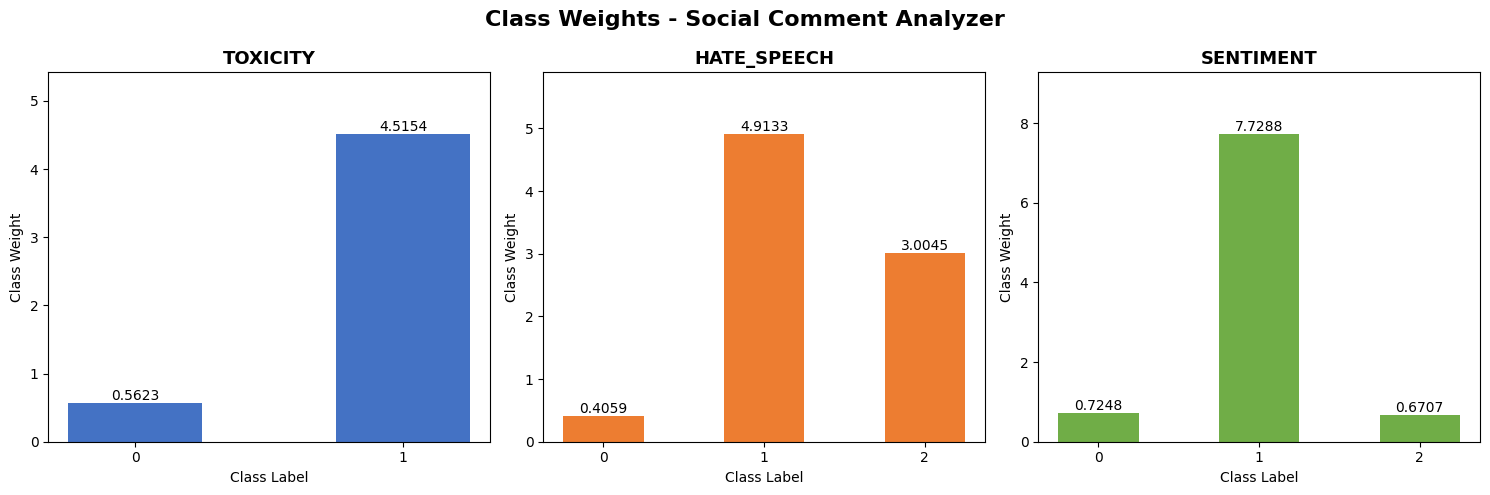

Đã xuất biểu đồ thành công!
Đường dẫn: /content/section_4_3/class_weights.PNG


In [19]:

# ==================================================
# 4.3 - BƯỚC 3.6: VẼ BIỂU ĐỒ CLASS WEIGHTS
# ==================================================

import matplotlib.pyplot as plt
import os

# Tạo biểu đồ cho 3 bài toán
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = ['#4472C4', '#ED7D31', '#70AD47']

for i, (name, weights) in enumerate(class_weights_dict.items()):

    labels = [str(k) for k in weights.keys()]
    values = list(weights.values())

    bars = axes[i].bar(
        labels,
        values,
        color=colors[i],
        width=0.5
    )

    axes[i].set_title(
        name.upper(),
        fontsize=13,
        fontweight='bold'
    )

    axes[i].set_xlabel('Class Label')
    axes[i].set_ylabel('Class Weight')

    axes[i].set_ylim(0, max(values) * 1.2)

    # Hiển thị giá trị trên từng cột
    for bar in bars:
        height = bar.get_height()

        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f'{height:.4f}',
            ha='center',
            va='bottom',
            fontsize=10
        )

plt.suptitle(
    'Class Weights - Social Comment Analyzer',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

# Lưu file PNG
save_path = f"{output_dir}/class_weights.PNG"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Đã xuất biểu đồ thành công!")
print("Đường dẫn:", save_path)


In [20]:

# ==================================================
# 4.3 - BƯỚC 3.7: HUGGING FACE DATASET PACKAGING
# ==================================================

from datasets import Dataset, DatasetDict, load_from_disk
from transformers import AutoTokenizer
import os
import numpy as np

# Sử dụng đúng PhoBERT của dự án
MODEL_NAME = "vinai/phobert-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Kiểm tra MAX_LEN từ mục 4.2
if "MAX_LEN" not in globals():
    raise ValueError("Hãy chạy mục 4.2 để tạo MAX_LEN trước!")

print("MAX_LEN =", MAX_LEN)

hf_datasets = {}

# Hàm Tokenize văn bản đã tách từ bằng PyVi
def tokenize_batch(batch):
    return tokenizer(
        batch["text_segmented"],
        padding="max_length",
        truncation=True,
        max_length=int(MAX_LEN)
    )

# Đóng gói riêng cho từng bài toán
for name, splits in split_datasets.items():

    print("\n" + "=" * 50)
    print("PACKAGING:", name.upper())
    print("=" * 50)

    dataset_dict = DatasetDict()

    # Tạo Dataset cho Train, Validation và Test
    for split_name in ["train", "validation", "test"]:

        data = splits[split_name][
            ["text_segmented", "labels"]
        ].copy()

        # Chuẩn hóa kiểu dữ liệu nhãn
        data["labels"] = data["labels"].astype("int64")

        # Chuyển Pandas sang Hugging Face Dataset
        dataset_dict[split_name] = Dataset.from_pandas(
            data.reset_index(drop=True),
            preserve_index=False
        )

    # Tokenize toàn bộ Dataset
    dataset_dict = dataset_dict.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text_segmented"]
    )

    # Định dạng đầu vào cho PyTorch
    dataset_dict.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask",
            "labels"
        ]
    )

    # Lưu Dataset
    save_dir = f"{output_dir}/{name}/hf_dataset"

    dataset_dict.save_to_disk(save_dir)

    # Lưu vào biến để sử dụng tiếp
    hf_datasets[name] = dataset_dict

    print("\nCẤU TRÚC DATASET:")
    print(dataset_dict)

    # Kiểm tra một sample
    sample = dataset_dict["train"][0]

    print("\nKIỂM TRA SAMPLE:")
    print("Input IDs:", sample["input_ids"].shape)
    print("Attention Mask:", sample["attention_mask"].shape)
    print("Label:", sample["labels"].item())

    assert len(sample["input_ids"]) == int(MAX_LEN)
    assert len(sample["attention_mask"]) == int(MAX_LEN)

    print("\nĐÃ LƯU:", save_dir)

print("\n=====================================")
print("DATASET PACKAGING COMPLETED!")
print("=====================================")


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

MAX_LEN = 64

PACKAGING: TOXICITY


Map:   0%|          | 0/7938 [00:00<?, ? examples/s]

... (16 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/12938 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1617 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1618 [00:00<?, ? examples/s]


CẤU TRÚC DATASET:
DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 12938
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 1617
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 1618
    })
})

KIỂM TRA SAMPLE:
Input IDs: torch.Size([64])
Attention Mask: torch.Size([64])
Label: 2

ĐÃ LƯU: /content/section_4_3/sentiment/hf_dataset

DATASET PACKAGING COMPLETED!


 # 4. Train Toxicity model - Hoàng Minh


In [54]:
import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import load_from_disk
from sklearn.utils.class_weight import compute_class_weight

# 1. Thư mục lưu kết quả model và biểu đồ
SAVE_DIR = "/content/drive/MyDrive/Project1/toxicity_model_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Khởi tạo tokenizer từ model_name đã khai báo ở Mục 3
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [55]:
# 2. Lấy dữ liệu Toxicity đã đóng gói từ Mục 4.3
if 'hf_datasets' in globals() and 'toxicity' in hf_datasets:
    toxicity_dataset = hf_datasets['toxicity']
elif os.path.exists("/content/section_4_3/toxicity/hf_dataset"):
    toxicity_dataset = load_from_disk("/content/section_4_3/toxicity/hf_dataset")
else:
    # Dự phòng nếu nhóm lưu dữ liệu ở file df_segmented.csv
    from datasets import Dataset, DatasetDict
    df_seg_path = "/content/drive/MyDrive/Project1/df_segmented.csv"
    if not os.path.exists(df_seg_path):
        df_seg_path = "df_segmented.csv"
    df_all = pd.read_csv(df_seg_path)
    df_tox = df_all[df_all['task'] == 'toxicity'].copy().reset_index(drop=True)
    df_tox['label'] = df_tox['label_raw'].astype(int)

    from sklearn.model_selection import train_test_split
    tr, ts = train_test_split(df_tox, test_size=0.2, random_state=42, stratify=df_tox['label'])
    va, ts = train_test_split(ts, test_size=0.5, random_state=42, stratify=ts['label'])

    def tokenize_function(examples):
        return tokenizer(examples['text_segmented'], padding="max_length", truncation=True, max_length=128)

    ds_tr = Dataset.from_pandas(tr).map(tokenize_function, batched=True)
    ds_va = Dataset.from_pandas(va).map(tokenize_function, batched=True)
    ds_ts = Dataset.from_pandas(ts).map(tokenize_function, batched=True)
    toxicity_dataset = DatasetDict({'train': ds_tr, 'validation': ds_va, 'test': ds_ts})

print("✅ Đã chuẩn bị xong dữ liệu Toxicity:")
print(toxicity_dataset)

✅ Đã chuẩn bị xong dữ liệu Toxicity:
DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 7938
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 992
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 993
    })
})


In [56]:
# 3. Chuẩn bị Trọng số lớp (Class Weights) cho hàm Loss (0: non-toxic, 1: toxic)
if 'class_weights_dict' in globals() and 'toxicity' in class_weights_dict:
    weights_list = [
        class_weights_dict['toxicity'][0],
        class_weights_dict['toxicity'][1]
    ]
else:
    train_labels = np.array(toxicity_dataset['train']['label'] if 'label' in toxicity_dataset['train'].column_names else toxicity_dataset['train']['labels'])
    unique_classes = np.unique(train_labels)
    computed_weights = compute_class_weight('balanced', classes=unique_classes, y=train_labels)
    weights_list = computed_weights.tolist()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights_tensor = torch.tensor(weights_list, dtype=torch.float).to(device)
print("Device sử dụng:", device)
print("Trọng số Class Weights đưa vào Loss:", class_weights_tensor)

# 4. Kế thừa Trainer để tối ưu hàm Loss có trọng số (Macro F1 ưu tiên)
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# 5. Hàm tính toán chỉ số đánh giá (Bắt buộc Macro F1)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )

    return {
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro
    }

Device sử dụng: cuda
Trọng số Class Weights đưa vào Loss: tensor([0.5623, 4.5154], device='cuda:0')


In [57]:
# 6. Nạp kiến trúc PhoBERT cho 2 nhãn phân loại (Toxicity)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: "non-toxic", 1: "toxic"},
    label2id={"non-toxic": 0, "toxic": 1}
)

training_args = TrainingArguments(
    output_dir=f"{SAVE_DIR}/checkpoints",
    num_train_epochs=3,                     # Huấn luyện chuẩn 3 epoch
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",                  # Đánh giá sau mỗi epoch
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",       # Tự động chọn epoch có Macro F1 cao nhất
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=toxicity_dataset['train'],
    eval_dataset=toxicity_dataset['validation'],
    compute_metrics=compute_metrics
)

print("🚀 Bắt đầu huấn luyện mô hình Toxicity PhoBERT...")
trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


🚀 Bắt đầu huấn luyện mô hình Toxicity PhoBERT...


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.516800,0.482442,0.768145,0.628745,0.770150,0.639899
2,0.385395,0.544038,0.845766,0.672398,0.774016,0.702016
3,0.291051,0.594445,0.854839,0.676700,0.759225,0.704126


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=747, training_loss=0.4060792501671726, metrics={'train_runtime': 132.8219, 'train_samples_per_second': 179.293, 'train_steps_per_second': 5.624, 'total_flos': 783215834042880.0, 'train_loss': 0.4060792501671726, 'epoch': 3.0})

Tiến hành đánh giá trên tập độc lập Test...


Accuracy        : 0.8681
Precision Macro : 0.6971
Recall Macro    : 0.7826
F1-score Macro  : 0.7269 (Chỉ số ưu tiên)

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   non-toxic       0.96      0.89      0.92       883
       toxic       0.44      0.67      0.53       110

    accuracy                           0.87       993
   macro avg       0.70      0.78      0.73       993
weighted avg       0.90      0.87      0.88       993



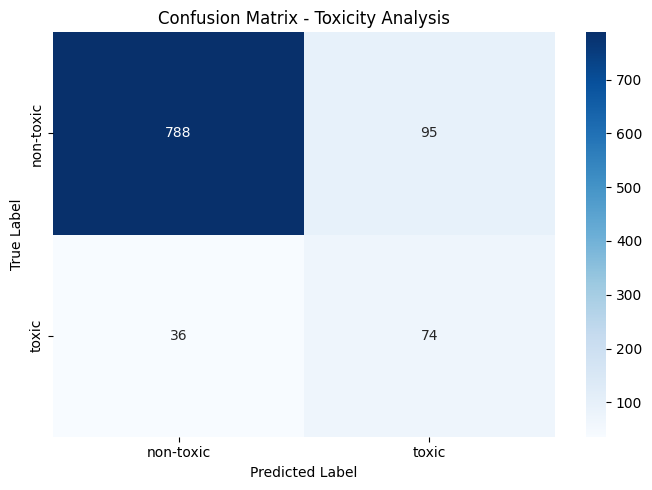

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


[Hoàn thành] Toàn bộ Model, Chỉ số và Biểu đồ đã lưu tại:
-> /content/drive/MyDrive/Project1/toxicity_model_results


In [58]:
print("Tiến hành đánh giá trên tập độc lập Test...")
test_predictions = trainer.predict(toxicity_dataset['test'])

# Lấy nhãn thực tế
if 'labels' in toxicity_dataset['test'].column_names:
    y_true = np.array(toxicity_dataset['test']['labels'])
else:
    y_true = np.array(toxicity_dataset['test']['label'])

y_pred = np.argmax(test_predictions.predictions, axis=-1)
target_names = ["non-toxic", "toxic"]

# 1. Tính toán các chỉ số cơ bản
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
cls_report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
cls_report_str = classification_report(y_true, y_pred, target_names=target_names)
cm = confusion_matrix(y_true, y_pred)

# 2. In trực quan ra màn hình
print("=" * 60)
print(f"Accuracy        : {acc:.4f}")
print(f"Precision Macro : {prec:.4f}")
print(f"Recall Macro    : {rec:.4f}")
print(f"F1-score Macro  : {f1:.4f} (Chỉ số ưu tiên)")
print("=" * 60)
print("\n--- CLASSIFICATION REPORT ---")
print(cls_report_str)

# 3. Vẽ và lưu Confusion Matrix ra file ảnh
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix - Toxicity Analysis")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
cm_path = f"{SAVE_DIR}/confusion_matrix_toxicity.png"
plt.savefig(cm_path, dpi=300)
plt.show()

# 4. Lưu toàn bộ chỉ số vào file CSV trên Google Drive
metrics_df = pd.DataFrame(cls_report_dict).transpose()
metrics_df.to_csv(f"{SAVE_DIR}/toxicity_classification_report.csv")

# 5. Lưu lại Model và Tokenizer hoàn thiện
model.save_pretrained(f"{SAVE_DIR}/final_model")
tokenizer.save_pretrained(f"{SAVE_DIR}/final_model")
print(f"\n[Hoàn thành] Toàn bộ Model, Chỉ số và Biểu đồ đã lưu tại:\n-> {SAVE_DIR}")

# 5. Train Hate Speech model - Tú

In [30]:
# ============================================================
# 5. TRAIN HATE SPEECH MODEL - BƯỚC 1: SETUP
# ============================================================

import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_from_disk
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

# Để kết quả có thể tái lập
set_seed(42)

# ------------------------------------------------------------
# Kiểm tra GPU
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Chưa bật GPU!")

# ------------------------------------------------------------
# Cấu hình
# ------------------------------------------------------------

SAVE_DIR = "/content/drive/MyDrive/Project1/hate_speech_model_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Sử dụng model_name đã khai báo ở Mục 3
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("\nModel:", model_name)
print("Save directory:", SAVE_DIR)

Device: cuda
GPU: Tesla T4

Model: vinai/phobert-base-v2
Save directory: /content/drive/MyDrive/Project1/hate_speech_model_results


In [31]:
# ============================================================
# RETOKENIZE HATE SPEECH BẰNG PHOBERT-BASE-V2
# ============================================================

import pandas as pd

from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer

# Sử dụng model_name đã khai báo ở Mục 3
MAX_LEN = 64

tokenizer = AutoTokenizer.from_pretrained(model_name)

base_dir = "/content/section_4_3/hate_speech"

# Đọc 3 tập đã chia từ mục 4.3
train_df = pd.read_csv(f"{base_dir}/train.csv")
val_df   = pd.read_csv(f"{base_dir}/validation.csv")
test_df  = pd.read_csv(f"{base_dir}/test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nColumns:")
print(train_df.columns.tolist())

# Chỉ giữ cột cần thiết
def make_dataset(df):
    temp = df[["text_segmented", "labels"]].copy()
    temp["labels"] = temp["labels"].astype("int64")

    return Dataset.from_pandas(
        temp,
        preserve_index=False
    )

hate_dataset_v2 = DatasetDict({
    "train": make_dataset(train_df),
    "validation": make_dataset(val_df),
    "test": make_dataset(test_df)
})

def tokenize_batch(batch):
    return tokenizer(
        batch["text_segmented"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN
    )

hate_dataset_v2 = hate_dataset_v2.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text_segmented"]
)

hate_dataset_v2.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

# Lưu phiên bản mới
save_path = (
    "/content/section_4_3/"
    "hate_speech/hf_dataset_phobert_v2"
)

hate_dataset_v2.save_to_disk(save_path)

print("\nDONE!")
print(hate_dataset_v2)
print("Đã lưu:", save_path)

sample = hate_dataset_v2["train"][0]

print("\nSample:")
print("input_ids:", sample["input_ids"].shape)
print("attention_mask:", sample["attention_mask"].shape)
print("label:", sample["labels"].item())

Train: 23525
Validation: 2941
Test: 2941

Columns:
['text', 'label_raw', 'task', 'text_cleaned', 'text_segmented', 'labels']


Map:   0%|          | 0/23525 [00:00<?, ? examples/s]

Map:   0%|          | 0/2941 [00:00<?, ? examples/s]

Map:   0%|          | 0/2941 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/23525 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2941 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2941 [00:00<?, ? examples/s]


DONE!
DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 23525
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 2941
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 2941
    })
})
Đã lưu: /content/section_4_3/hate_speech/hf_dataset_phobert_v2

Sample:
input_ids: torch.Size([64])
attention_mask: torch.Size([64])
label: 0


In [32]:
# ============================================================
# HATE SPEECH - CLASS WEIGHTS
# ============================================================

import numpy as np
import torch

from sklearn.utils.class_weight import compute_class_weight

# Lấy label của TRAIN SET
y_train = np.array(
    hate_dataset_v2["train"]["labels"]
)

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights_tensor = torch.tensor(
    weights,
    dtype=torch.float
).to(device)

print("Số mẫu từng lớp:")

unique, counts = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count}")

print("\nClass Weights:")

for label, weight in zip(classes, weights):
    print(f"Class {label}: {weight:.4f}")

print("\nTensor:")
print(class_weights_tensor)

Số mẫu từng lớp:
Class 0: 19319
Class 1: 1596
Class 2: 2610

Class Weights:
Class 0: 0.4059
Class 1: 4.9133
Class 2: 3.0045

Tensor:
tensor([0.4059, 4.9133, 3.0045], device='cuda:0')


In [33]:
import torch.nn as nn

from transformers import Trainer
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.get("labels")

        outputs = model(**inputs)
        logits = outputs.get("logits")

        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights_tensor
        )

        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        preds
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            preds,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    }

print("WeightedTrainer ready!")

WeightedTrainer ready!


In [34]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label={
        0: "CLEAN",
        1: "OFFENSIVE",
        2: "HATE"
    },
    label2id={
        "CLEAN": 0,
        "OFFENSIVE": 1,
        "HATE": 2
    }
)

print("Model loaded!")
print(model.config.id2label)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded!
{0: 'CLEAN', 1: 'OFFENSIVE', 2: 'HATE'}


In [35]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/Project1/hate_speech_model_results/checkpoints",

    num_train_epochs=3,

    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1_macro",
    greater_is_better=True,

    logging_steps=50,

    fp16=True,

    report_to="none",

    seed=42
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=hate_dataset_v2["train"],
    eval_dataset=hate_dataset_v2["validation"],

    compute_metrics=compute_metrics
)

print("Trainer ready!")

Trainer ready!


In [40]:
train_result = trainer.train()
# Đường dẫn lưu model cuối cùng
FINAL_MODEL_DIR = (
    "/content/drive/MyDrive/Project1/"
    "hate_speech_model_results/final_model"
)

# Lưu mô hình tốt nhất sau khi Trainer hoàn tất
trainer.save_model(FINAL_MODEL_DIR)

# Lưu tokenizer tương ứng
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Đã lưu model và tokenizer!")

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.553427,0.722573,0.828630,0.616542,0.731435,0.656600
2,0.390632,0.940551,0.856171,0.654987,0.719041,0.681428
3,0.246861,1.119787,0.867052,0.671689,0.721045,0.693337


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu model và tokenizer!


In [41]:
import os

SAVE_DIR = "/content/drive/MyDrive/Project1/hate_speech_model_results"
FINAL_PATH = os.path.join(SAVE_DIR, "final_model")

os.makedirs(FINAL_PATH, exist_ok=True)

# Lưu tokenizer đang sử dụng trong phần huấn luyện Hate Speech
tokenizer.save_pretrained(FINAL_PATH)

print("Đường dẫn:", FINAL_PATH)
print("Các file đã lưu:")
for file in os.listdir(FINAL_PATH):
    print("-", file)

Đường dẫn: /content/drive/MyDrive/Project1/hate_speech_model_results/final_model
Các file đã lưu:
- tokenizer_config.json
- added_tokens.json
- vocab.txt
- bpe.codes
- config.json
- model.safetensors
- training_args.bin


#6. Train Sentiment model - Hưng

In [21]:
import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import load_from_disk

# 1. Thư mục lưu kết quả model và biểu đồ
SAVE_DIR = "/content/drive/MyDrive/Project1/sentiment_model_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# 2. Lấy dữ liệu Sentiment đã đóng gói từ Mục 4.3
if 'hf_datasets' in globals() and 'sentiment' in hf_datasets:
    sentiment_dataset = hf_datasets['sentiment']
else:
    sentiment_dataset = load_from_disk("/content/section_4_3/sentiment/hf_dataset")

# 3. Chuẩn bị Trọng số lớp (Class Weights) cho hàm Loss
# Sentiment gồm 3 lớp: 0: negative, 1: neutral, 2: positive
weights_list = [
    class_weights_dict['sentiment'][0],
    class_weights_dict['sentiment'][1],
    class_weights_dict['sentiment'][2]
]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights_tensor = torch.tensor(weights_list, dtype=torch.float).to(device)
print("Device sử dụng:", device)
print("Trọng số Class Weights đưa vào Loss:", class_weights_tensor)

# 4. Kế thừa Trainer để tối ưu hàm Loss có trọng số (Macro F1 ưu tiên)
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# 5. Hàm tính toán chỉ số đánh giá (Bắt buộc Macro F1)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )

    return {
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro
    }

# 6. Nạp kiến trúc PhoBERT cho 3 nhãn phân loại
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
)

Device sử dụng: cuda
Trọng số Class Weights đưa vào Loss: tensor([0.7248, 7.7288, 0.6707], device='cuda:0')


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [22]:
training_args = TrainingArguments(
    output_dir=f"{SAVE_DIR}/checkpoints",
    num_train_epochs=3,                     # Huấn luyện chuẩn từ 3-4 epoch
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",                  # Đánh giá sau mỗi epoch
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",       # Tự động chọn epoch có Macro F1 cao nhất
    greater_is_better=True,
    logging_steps=50,
    report_to="none"
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=sentiment_dataset['train'],
    eval_dataset=sentiment_dataset['validation'],
    compute_metrics=compute_metrics
)

print("Bắt đầu huấn luyện mô hình Sentiment PhoBERT...")
trainer.train()

Bắt đầu huấn luyện mô hình Sentiment PhoBERT...


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.456861,0.316262,0.930736,0.795133,0.882346,0.824081
2,0.348643,0.378276,0.952999,0.869267,0.880726,0.874784
3,0.335881,0.353893,0.948670,0.854223,0.890630,0.870490


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1215, training_loss=0.3813816765208303, metrics={'train_runtime': 547.0428, 'train_samples_per_second': 70.952, 'train_steps_per_second': 2.221, 'total_flos': 1276560524461824.0, 'train_loss': 0.3813816765208303, 'epoch': 3.0})

Tiến hành đánh giá trên tập độc lập Test...


Accuracy        : 0.9468
Precision Macro : 0.8487
Recall Macro    : 0.8591
F1-score Macro  : 0.8537 (Chỉ số ưu tiên)

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

    negative       0.95      0.96      0.96       744
     neutral       0.62      0.66      0.64        70
    positive       0.97      0.96      0.96       804

    accuracy                           0.95      1618
   macro avg       0.85      0.86      0.85      1618
weighted avg       0.95      0.95      0.95      1618



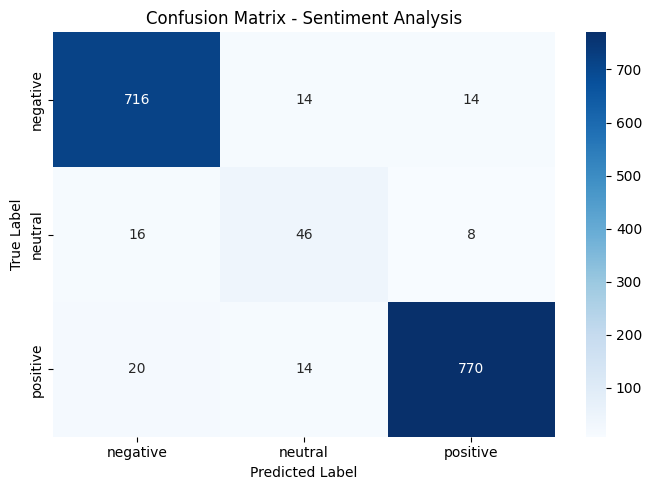

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


[Hoàn thành 6] Toàn bộ Model, Chỉ số và Biểu đồ đã lưu tại:
-> /content/drive/MyDrive/Project1/sentiment_model_results


In [23]:
print("Tiến hành đánh giá trên tập độc lập Test...")
test_predictions = trainer.predict(sentiment_dataset['test'])
y_true = np.array(sentiment_dataset['test']['labels'])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
target_names = ["negative", "neutral", "positive"]

# 1. Tính toán các chỉ số cơ bản
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
cls_report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
cls_report_str = classification_report(y_true, y_pred, target_names=target_names)
cm = confusion_matrix(y_true, y_pred)

# 2. In trực quan ra màn hình
print("=" * 60)
print(f"Accuracy        : {acc:.4f}")
print(f"Precision Macro : {prec:.4f}")
print(f"Recall Macro    : {rec:.4f}")
print(f"F1-score Macro  : {f1:.4f} (Chỉ số ưu tiên)")
print("=" * 60)
print("\n--- CLASSIFICATION REPORT ---")
print(cls_report_str)

# 3. Vẽ và lưu Confusion Matrix ra file ảnh
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix - Sentiment Analysis")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
cm_path = f"{SAVE_DIR}/confusion_matrix_sentiment.png"
plt.savefig(cm_path, dpi=300)
plt.show()

# 4. Lưu toàn bộ chỉ số vào file Excel / CSV trên Google Drive
metrics_df = pd.DataFrame(cls_report_dict).transpose()
metrics_df.to_csv(f"{SAVE_DIR}/sentiment_classification_report.csv")

# 5. Lưu lại Model và Tokenizer hoàn thiện
model.save_pretrained(f"{SAVE_DIR}/final_model")
tokenizer.save_pretrained(f"{SAVE_DIR}/final_model")
print(f"\n[Hoàn thành 6] Toàn bộ Model, Chỉ số và Biểu đồ đã lưu tại:\n-> {SAVE_DIR}")

#7. Đánh giá 3 model - Bình Minh

#8. Phần thử nghiệm - Bình Minh


#9. Đánh giá thông số - Vương

#10. Lưu model - Vương


In [42]:
import os
import torch
import pandas as pd

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Chọn thiết bị chạy
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Các thư mục model đã lưu trên Google Drive
MODEL_PATHS = {
    "toxicity": (
        "/content/drive/MyDrive/Project1/"
        "toxicity_model_results/final_model"
    ),
    "hate_speech": (
        "/content/drive/MyDrive/Project1/"
        "hate_speech_model_results/final_model"
    ),
    "sentiment": (
        "/content/drive/MyDrive/Project1/"
        "sentiment_model_results/final_model"
    )
}

models = {}
tokenizers = {}

for task, path in MODEL_PATHS.items():
    if not os.path.isdir(path):
        print(f"CHƯA TÌM THẤY MODEL: {path}")
        continue

    tokenizers[task] = AutoTokenizer.from_pretrained(path)

    models[task] = AutoModelForSequenceClassification.from_pretrained(
        path
    ).to(device)

    models[task].eval()

    print(f"Đã nạp mô hình: {task}")

print("Thiết bị:", device)
print("Số mô hình đã nạp:", len(models))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đã nạp mô hình: toxicity


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đã nạp mô hình: hate_speech


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đã nạp mô hình: sentiment
Thiết bị: cuda
Số mô hình đã nạp: 3


In [43]:
LABELS = {
    "toxicity": {
        0: "NON-TOXIC",
        1: "TOXIC"
    },
    "hate_speech": {
        0: "CLEAN",
        1: "OFFENSIVE",
        2: "HATE"
    },
    "sentiment": {
        0: "NEGATIVE",
        1: "NEUTRAL",
        2: "POSITIVE"
    }
}


def predict_one(task, text):
    if task not in models:
        raise ValueError(f"Chưa nạp được mô hình: {task}")

    tokenizer = tokenizers[task]
    model = models[task]

    # Tiền xử lý phải nhất quán với lúc training.
    # Nếu đã chạy cell định nghĩa clean_text() trong notebook,
    # dùng lại chính hàm đó.
    processed_text = clean_text(text)

    inputs = tokenizer(
        processed_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted_id = int(torch.argmax(probabilities).item())

    label_map = LABELS[task]

    return {
        "task": task,
        "label": label_map.get(
            predicted_id, f"LABEL_{predicted_id}"
        ),
        "confidence": float(probabilities[predicted_id]),
        "probabilities": {
            label_map.get(i, f"LABEL_{i}"): float(p)
            for i, p in enumerate(probabilities.cpu().tolist())
        }
    }

In [60]:
comment = """
Trẻ trâu không biết gì cả
"""

results = []

for task in ["toxicity", "hate_speech", "sentiment"]:
    if task in models:
        result = predict_one(task, comment)

        results.append({
            "Tiêu chí": task,
            "Nhãn dự đoán": result["label"],
            "Độ tin cậy (%)": round(
                result["confidence"] * 100, 2
            )
        })

print("BÌNH LUẬN:", comment)
display(pd.DataFrame(results))

BÌNH LUẬN: 
Trẻ trâu không biết gì cả



,Tiêu chí,Nhãn dự đoán,Độ tin cậy (%)
0,toxicity,TOXIC,96.48
1,hate_speech,OFFENSIVE,98.18
2,sentiment,NEGATIVE,96.74


In [61]:
import os
import shutil

BASE_DIR = "/content/drive/MyDrive/Project1"

MODEL_DIRS = [
    "toxicity_model_results/final_model",
    "hate_speech_model_results/final_model",
    "sentiment_model_results/final_model"
]

# Tạo thư mục chứa 3 mô hình
EXPORT_DIR = "/content/phoBERT_models"
os.makedirs(EXPORT_DIR, exist_ok=True)

for model_path in MODEL_DIRS:
    source = os.path.join(BASE_DIR, model_path)

    if not os.path.isdir(source):
        print(f"KHÔNG TÌM THẤY: {source}")
        continue

    task_name = model_path.split("/")[0].replace("_model_results", "")
    destination = os.path.join(EXPORT_DIR, task_name)

    shutil.copytree(source, destination, dirs_exist_ok=True)
    print(f"Đã sao chép: {task_name}")

# Nén thành ZIP
ZIP_PATH = shutil.make_archive(
    "/content/phoBERT_models",
    "zip",
    EXPORT_DIR
)

# Sao lưu thêm bản ZIP vào thư mục Project1 trên Google Drive
drive_zip_path = os.path.join(BASE_DIR, "phoBERT_models.zip")
try:
    shutil.copy2(ZIP_PATH, drive_zip_path)
    print("Đã lưu bản sao ZIP lên Drive:", drive_zip_path)
except Exception as e:
    print("Không thể lưu ZIP lên Drive:", e)

print("File ZIP local:", ZIP_PATH)

Đã sao chép: toxicity
Đã sao chép: hate_speech
Đã sao chép: sentiment
Đã lưu bản sao ZIP lên Drive: /content/drive/MyDrive/Project1/phoBERT_models.zip
File ZIP local: /content/phoBERT_models.zip
